# **Hourly Energy Consumption Forecast.**

In [1]:
# Importing Necessary Packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_excel(r"/content/PJMW_MW_Hourly.xlsx")
df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


In [3]:
# shape of the dataset

print("Shape of dataset:",df.shape)

Shape of dataset: (143206, 2)


In [4]:
# Info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


In [5]:
# Some more description

df.describe()

,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


We can see every information about the enery consumption in the form of mean, IQR= 25%, 50%, 75%, maximum and std deviation

In [6]:
# Checking the initial null values present or not

df.isnull().sum()

,0
Datetime,0
PJMW_MW,0


In [7]:
# Checking of the duplictaes, if present

df.duplicated().sum()

np.int64(0)

In [8]:
# There are no null values and duplicates as suh.
# We will simplify the data further to make the data more insightful

# **Exploratory Data Analysis (EDA)**
**Project Objective**

The objective of this project is to analyze historical PJM hourly electricity consumption data and understand the patterns that can help us forecast future energy consumption.

The EDA focuses on:

Understanding the dataset structure and data quality
Analyzing the overall long-term consumption trend
Studying hourly consumption patterns
Studying day-of-week and weekday/weekend patterns
Studying monthly and yearly trends
Understanding seasonal behavior
Comparing summer and winter daily patterns
Analyzing holiday and non-holiday consumption
Identifying potential outliers
Extracting useful observations for future feature engineering
The target variable is PJMW_MW, which represents electricity consumption in megawatts (MW).

EDA is performed before modeling so that we understand the data, identify important patterns, and determine which time-based characteristics may be useful for forecasting.

# **Convert and Sort Datetime**

In [9]:
# Datetime must be treated as a real date/time value. Sorting is important because this is a time-series dataset

In [10]:
df["Datetime"]=pd.to_datetime(df["Datetime"])
df=df.sort_values("Datetime")

In [11]:
# 1. Daylight-saving duplicates: average the two readings
df = df.groupby("Datetime", as_index=False)["PJMW_MW"].mean()

# 2. Add the missing hours (they appear as empty rows)
df = df.set_index("Datetime").asfreq("h")

# 3. The one impossible reading (487 MW on 2003-05-29)
df.loc[df["PJMW_MW"] < 1000, "PJMW_MW"] = np.nan

# 4. Fill all the gaps (31 values) by interpolation
df["PJMW_MW"] = df["PJMW_MW"].interpolate()

# 5. Clean 0,1,2... index and Datetime back as a normal column
df = df.reset_index()

# 6. Hourly time-indexed series for the time-series models later
ts = df.set_index("Datetime")["PJMW_MW"].asfreq("h")

# Quick check
print(df.shape, "| nulls:", df["PJMW_MW"].isnull().sum(), "| duplicate timestamps:", df["Datetime"].duplicated().sum())
print("ts frequency:", ts.index.freq, "| ts nulls:", ts.isnull().sum())

(143232, 2) | nulls: 0 | duplicate timestamps: 0
ts frequency: <Hour> | ts nulls: 0


**Earlier the Datetime was treated as a text which will not be useful, so by these it will be converted into real date/time value which can be treated effeciently**.

# **Check the Date Range**

In [12]:
print(df["Datetime"].min())
print(df["Datetime"].max())

2002-04-01 01:00:00
2018-08-03 00:00:00


In [13]:
# It tells us about the First & Last timestamp of the dataset

# **Create Simplified time features [breaking into simpler terms]**

In [14]:
df["Year"]=df["Datetime"].dt.year
df["Month"]=df["Datetime"].dt.month
df["monthname"]=df["Datetime"].dt.month_name()
df["Day"]=df["Datetime"].dt.day
df["Hour"]=df["Datetime"].dt.hour
df["DayOfWeek"]=df["Datetime"].dt.day_of_week

In [15]:
df.head()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek
0,2002-04-01 01:00:00,4374.0,2002,4,April,1,1,0
1,2002-04-01 02:00:00,4306.0,2002,4,April,1,2,0
2,2002-04-01 03:00:00,4322.0,2002,4,April,1,3,0
3,2002-04-01 04:00:00,4359.0,2002,4,April,1,4,0
4,2002-04-01 05:00:00,4436.0,2002,4,April,1,5,0


In [16]:
df.tail()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek
143227,2018-08-02 20:00:00,6545.0,2018,8,August,2,20,3
143228,2018-08-02 21:00:00,6496.0,2018,8,August,2,21,3
143229,2018-08-02 22:00:00,6325.0,2018,8,August,2,22,3
143230,2018-08-02 23:00:00,5892.0,2018,8,August,2,23,3
143231,2018-08-03 00:00:00,5489.0,2018,8,August,3,0,4


# **Analyze Weekends & Seasons**

In [17]:
df["Weekend"]=df["DayOfWeek"] >=5
df["Season"]=df["Month"].map({1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
                              6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",
                              11:"Autumn",12:"Winter"})

In [18]:
# DayOfWeek values 0–4 are Monday–Friday and 5–6 are Saturday–Sunday. The Season column makes it easi to compare Seasonal col

In [19]:
df.tail()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek,Weekend,Season
143227,2018-08-02 20:00:00,6545.0,2018,8,August,2,20,3,False,Summer
143228,2018-08-02 21:00:00,6496.0,2018,8,August,2,21,3,False,Summer
143229,2018-08-02 22:00:00,6325.0,2018,8,August,2,22,3,False,Summer
143230,2018-08-02 23:00:00,5892.0,2018,8,August,2,23,3,False,Summer
143231,2018-08-03 00:00:00,5489.0,2018,8,August,3,0,4,False,Summer


# **VISUALISATION**

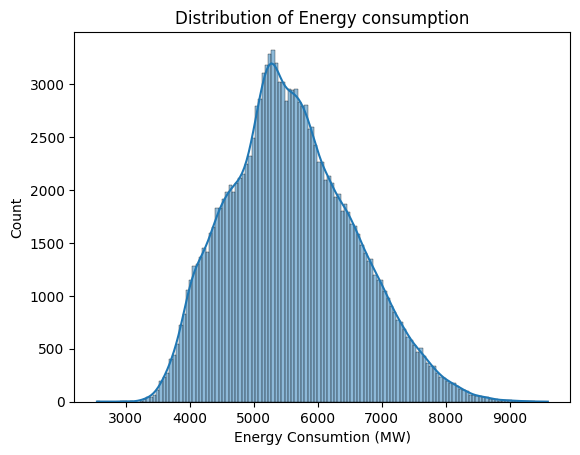

In [20]:
# Distribution of energy consumption

# Histplot

sns.histplot(df["PJMW_MW"],kde=True)
plt.title("Distribution of Energy consumption")
plt.xlabel("Energy Consumtion (MW)")
plt.show()

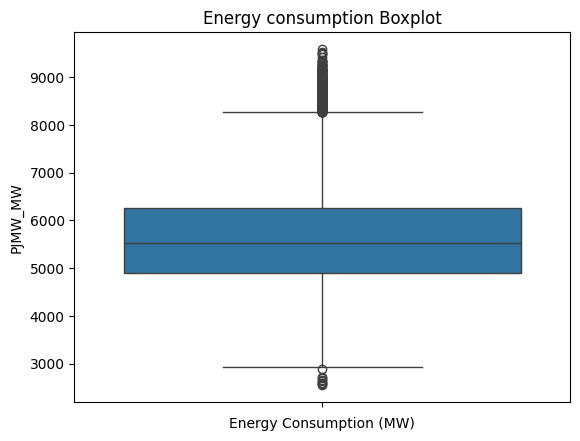

In [21]:
# Boxplot

sns.boxplot(df["PJMW_MW"])
plt.title("Energy consumption Boxplot")
plt.xlabel("Energy Consumption (MW)")
plt.show()

In [22]:
# The histogram shows the distribution level of the energy distribution

# The boxplot covers the possible extreme values, we are not going to cap them because they can show possible high rise in demand
#  during certain circumstances.'''

# **Long term trend**

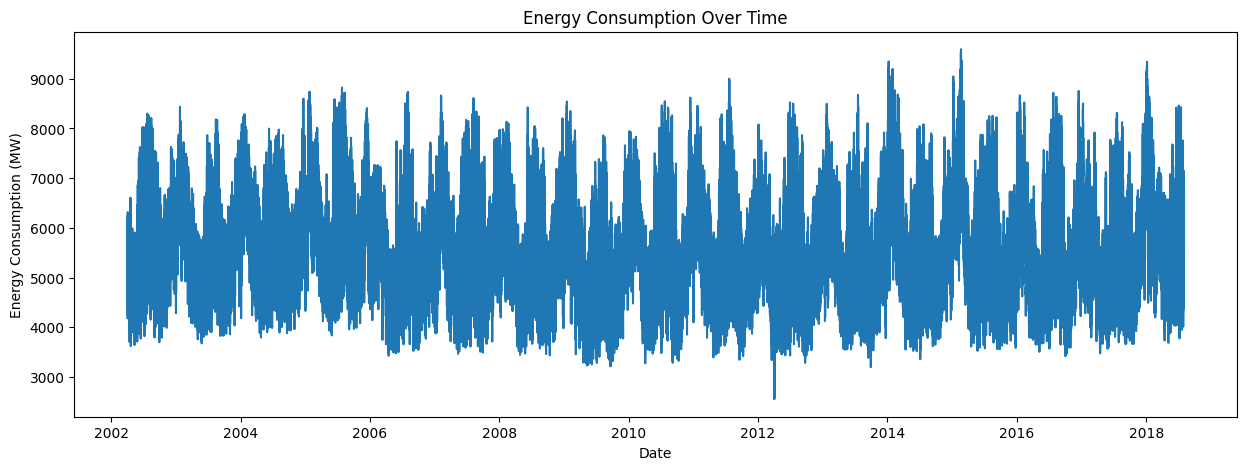

In [23]:
plt.figure(figsize=(15,5))
plt.plot(df["Datetime"], df["PJMW_MW"])
plt.title("Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")
plt.show()

In [24]:
# Shows how consumption changes in full time period & helps identify long term patterns

# **Hour-Wise consumption**

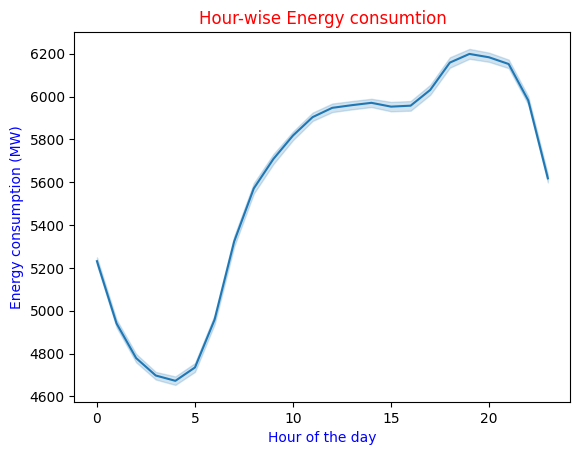

In [25]:
sns.lineplot(x="Hour",y="PJMW_MW",data=df)
plt.title("Hour-wise Energy consumtion",color="Red")
plt.xlabel("Hour of the day",color="Blue")
plt.ylabel("Energy consumption (MW)",color="Blue")
plt.show()

In [26]:
# Calculates consumptions for each hour of the day which given us the clear idea of the possible hourly consumption

# **Day of Week consumption**

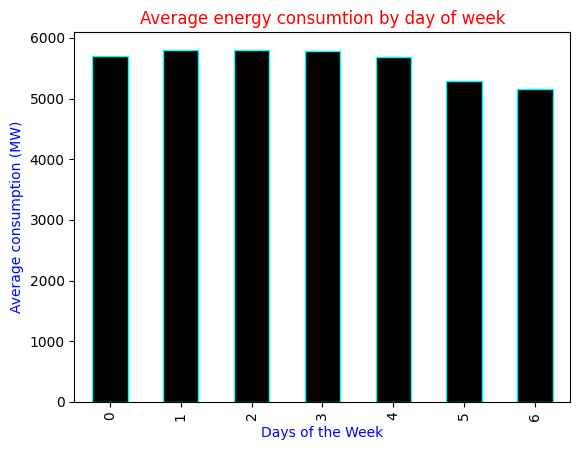

In [27]:
daily=df.groupby("DayOfWeek")["PJMW_MW"].mean()

daily.plot(kind="bar", color="black",edgecolor="cyan")
plt.title("Average energy consumtion by day of week",color="Red")
plt.xlabel("Days of the Week", color="Blue")
plt.ylabel("Average consumption (MW)",color="Blue")
plt.show()

In [28]:
# Compares average consumption across Monday to Sunday. 0 means Monday and 6 means Sunday.

# **Monthly consumption**

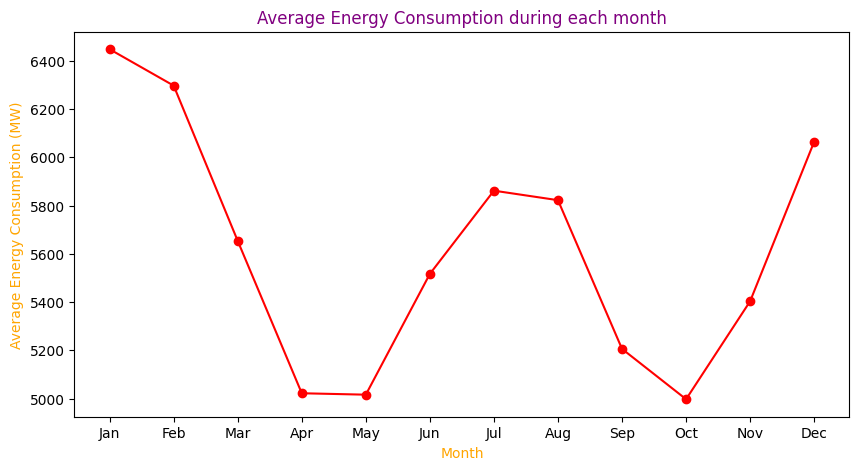

In [29]:
monthly=df.groupby("Month")["PJMW_MW"].mean()

monthly.plot(kind="line",color="Red",marker="o",figsize=(10,5))
plt.title("Average Energy Consumption during each month",color="Purple")
plt.xlabel("Month",color="Orange")
plt.ylabel("Average Energy Consumption (MW)",color="Orange")
plt.xticks(ticks=range(1,13), labels=["Jan","Feb","Mar","Apr","May","Jun",
                                        "Jul","Aug","Sep","Oct","Nov","Dec"])
plt.show()

In [30]:
# Shows average consumption for each month and helps identify recurring yearly patterns.

# **Seasonal Consumption**

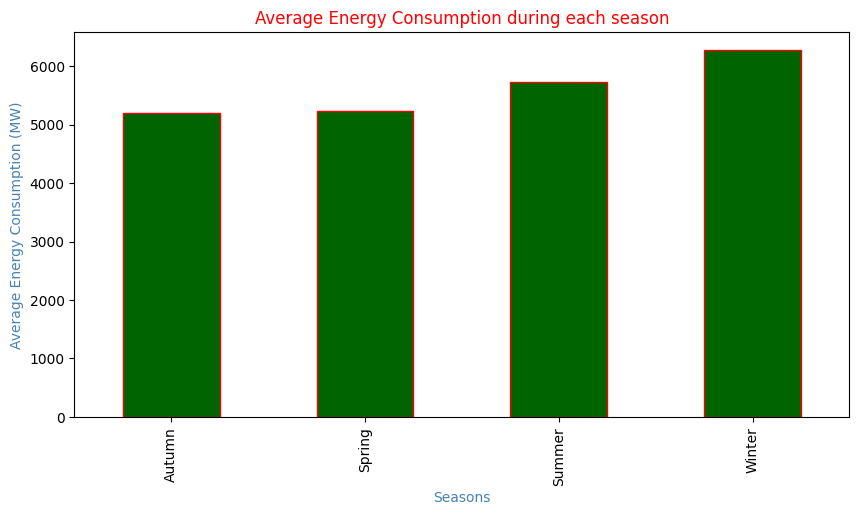

In [31]:
seasonal=df.groupby("Season")["PJMW_MW"].mean()

seasonal.plot(kind="bar",color="darkgreen",edgecolor="red",figsize=(10,5))
plt.title("Average Energy Consumption during each season",color="Red")
plt.xlabel("Seasons",color="steelblue")
plt.ylabel("Average Energy Consumption (MW)",color="steelblue")
plt.show()

In [32]:
# Compares Winter, Spring, Summer and Autumn. which shows the Energy consumption during each season

# **Season vs Hour [Key Analysis]**

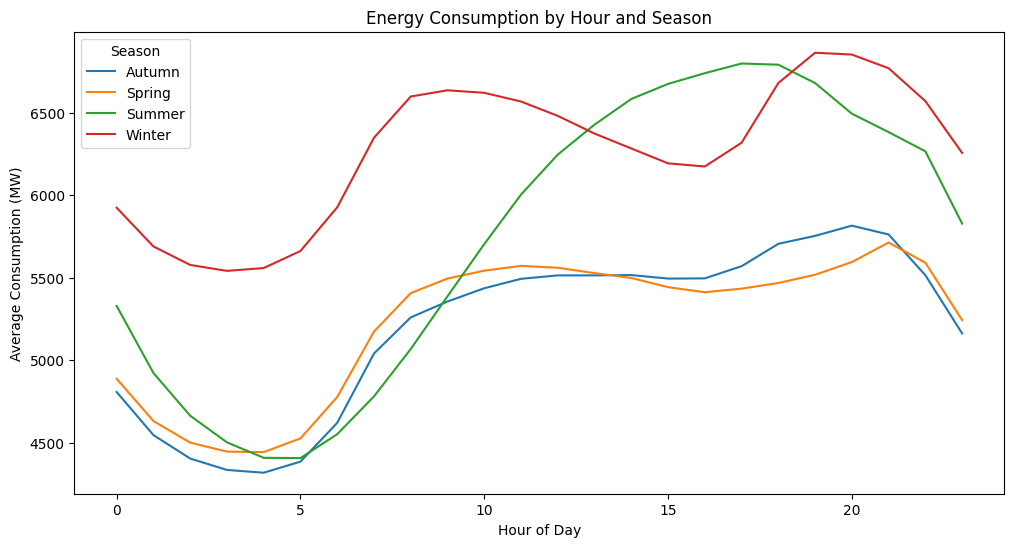

In [33]:
season_hour = df.groupby(["Season", "Hour"])["PJMW_MW"].mean().unstack()

season_hour.T.plot(figsize=(12,6))
plt.title("Energy Consumption by Hour and Season")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (MW)")
plt.show()

In [34]:
# Shows whether the daily hourly pattern changes by season. This is especially useful for comparing summer and winter behavior.

# **Weekend vs Weekday**

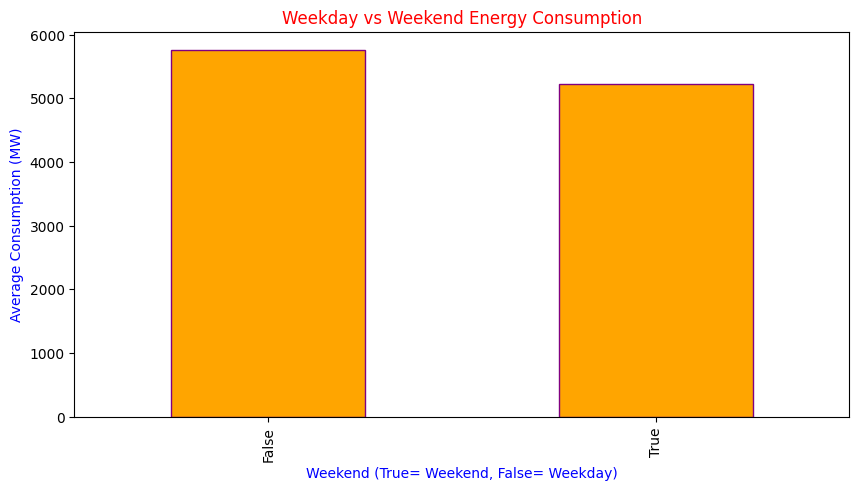

In [35]:
weekend = df.groupby("Weekend")["PJMW_MW"].mean()

weekend.plot(kind="bar",color="Orange",edgecolor="purple",figsize=(10,5))
plt.title("Weekday vs Weekend Energy Consumption",color="Red")
plt.xlabel("Weekend (True= Weekend, False= Weekday)",color="Blue")
plt.ylabel("Average Consumption (MW)",color="Blue")
plt.show()

In [36]:
# False means weekday and True means weekend. This gives a simple weekday/weekend comparison.

# **Holiday Analysis**

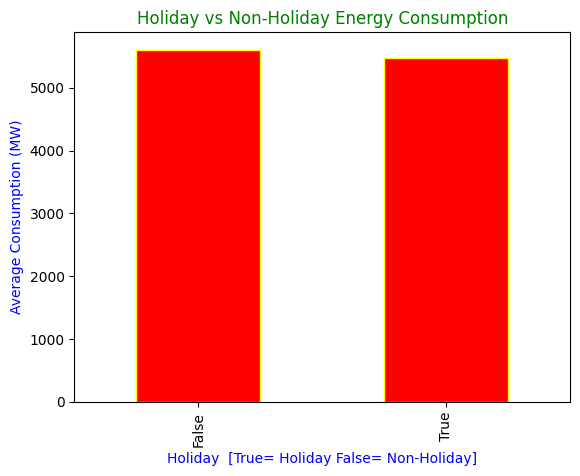

In [37]:
import holidays

# Creating US holiday calendar
us_holidays = holidays.US()

# Marking each row as holiday or non-holiday
df["Holiday"] = df["Datetime"].dt.date.apply(
    lambda x: x in us_holidays
)

# Comparing holiday and non-holiday average
holiday = df.groupby("Holiday")["PJMW_MW"].mean()

# Plotting
holiday.plot(kind="bar",color="red",edgecolor="yellow")

plt.title("Holiday vs Non-Holiday Energy Consumption",color="green")
plt.xlabel("Holiday  [True= Holiday False= Non-Holiday]",color="blue")
plt.ylabel("Average Consumption (MW)",color="blue")

plt.show()

**This code uses the US holiday calendar to identify whether each date in the PJM energy dataset is a holiday or a non-holiday.**

holidays.US() creates the US holiday calendar.
apply(lambda x: x in us_holidays) marks each date as True (Holiday) or False (Non-Holiday).
groupby("Holiday") calculates the average energy consumption for both categories.
The bar chart compares average electricity consumption on holidays vs non-holidays

# HEATMAP [Day*Hour] **bold text**

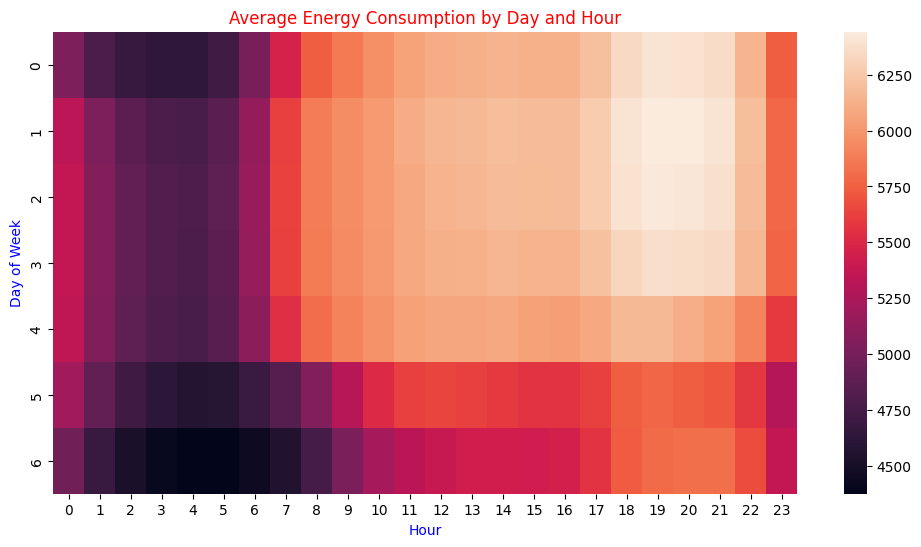

In [38]:
heatmap_data = df.groupby(["DayOfWeek", "Hour"])["PJMW_MW"].mean().unstack()

plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data)
plt.title("Average Energy Consumption by Day and Hour",color="Red")
plt.xlabel("Hour",color="Blue")
plt.ylabel("Day of Week",color="Blue")
plt.show()

In [39]:
# The heatmap combines day of week and hour, making repeated high- and low-consumption periods

# **EDA Conclusion**
The Exploratory Data Analysis of the PJM Hourly Energy Consumption dataset helped us understand the major patterns and factors affecting electricity consumption over time.

**Key Findings**
Time plays an important role: Energy consumption shows clear variations across different hours, days, months, and years.
Hourly patterns: Consumption changes throughout the day, indicating that certain hours consistently experience higher or lower energy demand.

**Day-wise variation:**
Weekdays and weekends show different consumption patterns, highlighting the effect of regular working and non-working days.
Seasonal impact: Energy consumption varies across Winter, Spring, Summer, and Autumn, showing that demand is influenced by seasonal conditions.

**Season × Hour relationship: **
The hourly consumption pattern is not the same across all seasons, making this an important factor for understanding energy demand.
Holiday effect: Comparing holidays with non-holidays helps identify changes in electricity usage during special days.
Long-term trend: The time-series analysis provides an overall view of how energy consumption has changed throughout the available period.

**Data quality: **
The dataset was examined for missing values, duplicates, data types, and other basic quality issues before performing the detailed analysis.

**Overall Conclusion**
Overall, the EDA shows that energy consumption is strongly influenced by time-based factors such as hour, day, month, season, weekends, and holidays. The visualizations and analysis provide a clear understanding of these recurring patterns.

These insights will be useful in the next stage of the project, where the identified time-based patterns can be used as important information for energy consumption forecasting and model building.

# **Data frame for Model Building**

In [40]:
df.head()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek,Weekend,Season,Holiday
0,2002-04-01 01:00:00,4374.0,2002,4,April,1,1,0,False,Spring,False
1,2002-04-01 02:00:00,4306.0,2002,4,April,1,2,0,False,Spring,False
2,2002-04-01 03:00:00,4322.0,2002,4,April,1,3,0,False,Spring,False
3,2002-04-01 04:00:00,4359.0,2002,4,April,1,4,0,False,Spring,False
4,2002-04-01 05:00:00,4436.0,2002,4,April,1,5,0,False,Spring,False


In [41]:
# Previous hour
df["Lag_1"] = df["PJMW_MW"].shift(1)
# Same hour previous day
df["Lag_24"] = df["PJMW_MW"].shift(24)
# Same hour previous week
df["Lag_168"] = df["PJMW_MW"].shift(168)

In [42]:
df.head()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek,Weekend,Season,Holiday,Lag_1,Lag_24,Lag_168
0,2002-04-01 01:00:00,4374.0,2002,4,April,1,1,0,False,Spring,False,NaN,NaN,NaN
1,2002-04-01 02:00:00,4306.0,2002,4,April,1,2,0,False,Spring,False,4374.0,NaN,NaN
2,2002-04-01 03:00:00,4322.0,2002,4,April,1,3,0,False,Spring,False,4306.0,NaN,NaN
3,2002-04-01 04:00:00,4359.0,2002,4,April,1,4,0,False,Spring,False,4322.0,NaN,NaN
4,2002-04-01 05:00:00,4436.0,2002,4,April,1,5,0,False,Spring,False,4359.0,NaN,NaN


In [43]:
print((df["Datetime"].diff().dropna() == pd.Timedelta("1h")).all())

True


In [44]:
df = df.dropna().reset_index(drop=True)

In [45]:
df.head()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek,Weekend,Season,Holiday,Lag_1,Lag_24,Lag_168
0,2002-04-08 01:00:00,4634.0,2002,4,April,8,1,0,False,Spring,False,4798.0,5002.0,4374.0
1,2002-04-08 02:00:00,4532.0,2002,4,April,8,2,0,False,Spring,False,4634.0,4858.0,4306.0
2,2002-04-08 03:00:00,4481.0,2002,4,April,8,3,0,False,Spring,False,4532.0,4864.5,4322.0
3,2002-04-08 04:00:00,4527.0,2002,4,April,8,4,0,False,Spring,False,4481.0,4871.0,4359.0
4,2002-04-08 05:00:00,4640.0,2002,4,April,8,5,0,False,Spring,False,4527.0,4909.0,4436.0


# **ENCODING**

In [46]:
# Keeping the df1 as a copy for the safe side

In [47]:
df1=df.copy()

In [48]:
df1[["Holiday", "Weekend"]] = df1[["Holiday", "Weekend"]].astype(int)

In [49]:
df1.head()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek,Weekend,Season,Holiday,Lag_1,Lag_24,Lag_168
0,2002-04-08 01:00:00,4634.0,2002,4,April,8,1,0,0,Spring,0,4798.0,5002.0,4374.0
1,2002-04-08 02:00:00,4532.0,2002,4,April,8,2,0,0,Spring,0,4634.0,4858.0,4306.0
2,2002-04-08 03:00:00,4481.0,2002,4,April,8,3,0,0,Spring,0,4532.0,4864.5,4322.0
3,2002-04-08 04:00:00,4527.0,2002,4,April,8,4,0,0,Spring,0,4481.0,4871.0,4359.0
4,2002-04-08 05:00:00,4640.0,2002,4,April,8,5,0,0,Spring,0,4527.0,4909.0,4436.0


In [50]:
from sklearn.preprocessing import OrdinalEncoder

enc = OrdinalEncoder(categories=[["Winter", "Spring", "Summer", "Autumn"]])
df1["Season"] = enc.fit_transform(df1[["Season"]]).astype(int)

In [51]:
df1.head()

,Datetime,PJMW_MW,Year,Month,monthname,Day,Hour,DayOfWeek,Weekend,Season,Holiday,Lag_1,Lag_24,Lag_168
0,2002-04-08 01:00:00,4634.0,2002,4,April,8,1,0,0,1,0,4798.0,5002.0,4374.0
1,2002-04-08 02:00:00,4532.0,2002,4,April,8,2,0,0,1,0,4634.0,4858.0,4306.0
2,2002-04-08 03:00:00,4481.0,2002,4,April,8,3,0,0,1,0,4532.0,4864.5,4322.0
3,2002-04-08 04:00:00,4527.0,2002,4,April,8,4,0,0,1,0,4481.0,4871.0,4359.0
4,2002-04-08 05:00:00,4640.0,2002,4,April,8,5,0,0,1,0,4527.0,4909.0,4436.0


# **Splitting the target and features**

In [52]:
target= df1[["PJMW_MW"]]
features= df1.drop(columns=["PJMW_MW","monthname"])

In [53]:
features.head()

,Datetime,Year,Month,Day,Hour,DayOfWeek,Weekend,Season,Holiday,Lag_1,Lag_24,Lag_168
0,2002-04-08 01:00:00,2002,4,8,1,0,0,1,0,4798.0,5002.0,4374.0
1,2002-04-08 02:00:00,2002,4,8,2,0,0,1,0,4634.0,4858.0,4306.0
2,2002-04-08 03:00:00,2002,4,8,3,0,0,1,0,4532.0,4864.5,4322.0
3,2002-04-08 04:00:00,2002,4,8,4,0,0,1,0,4481.0,4871.0,4359.0
4,2002-04-08 05:00:00,2002,4,8,5,0,0,1,0,4527.0,4909.0,4436.0


In [54]:
target.head()

,PJMW_MW
0,4634.0
1,4532.0
2,4481.0
3,4527.0
4,4640.0


# **Time Series format Model**

# **1) ARMIA**

In [55]:
# importing necessary packages

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error
import statsmodels.tsa.api as smt

In [56]:
# Plotting

In [57]:
# Decomposing the data

result = seasonal_decompose(df1["PJMW_MW"],model="additive", period=24)

**1- TREND PLOT**

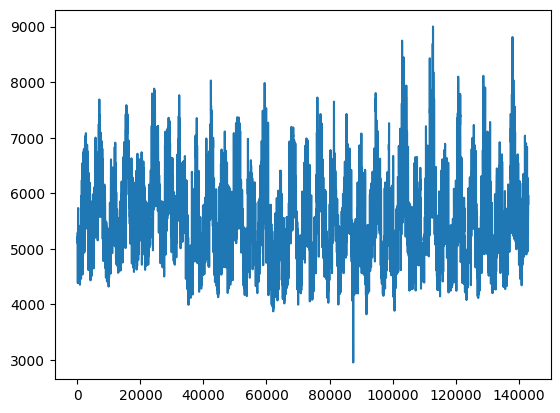

In [58]:
result.trend.plot()
plt.show()

**2- SEASONAL PLOT**

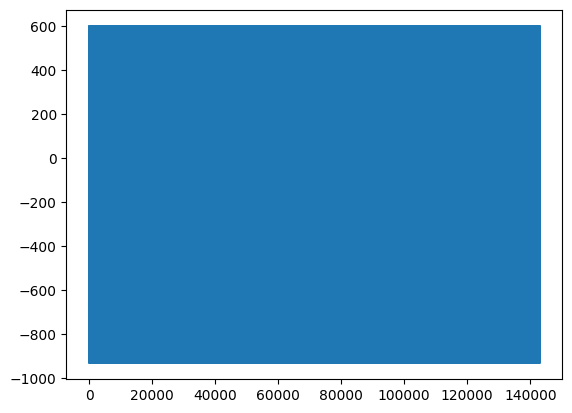

In [59]:
result.seasonal.plot()
plt.show()

**3- RESIDUAL PLOT**

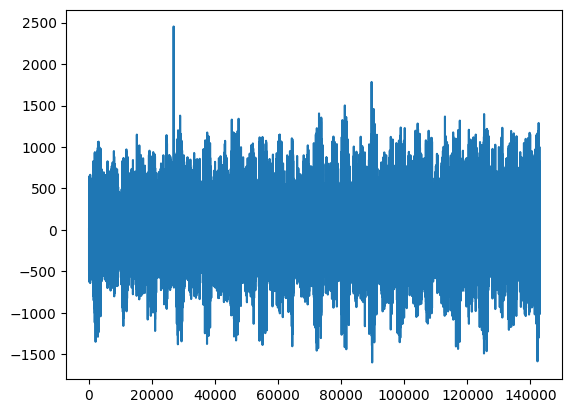

In [60]:
result.resid.plot()
plt.show()

# **Checking the Stationarity of data**

In [61]:
data = ts["2017-08-01":].to_frame("PJMW_MW")
data.head()

,PJMW_MW
Datetime,
2017-08-01 00:00:00,5309.0
2017-08-01 01:00:00,4920.0
2017-08-01 02:00:00,4692.0
2017-08-01 03:00:00,4451.0
2017-08-01 04:00:00,4405.0


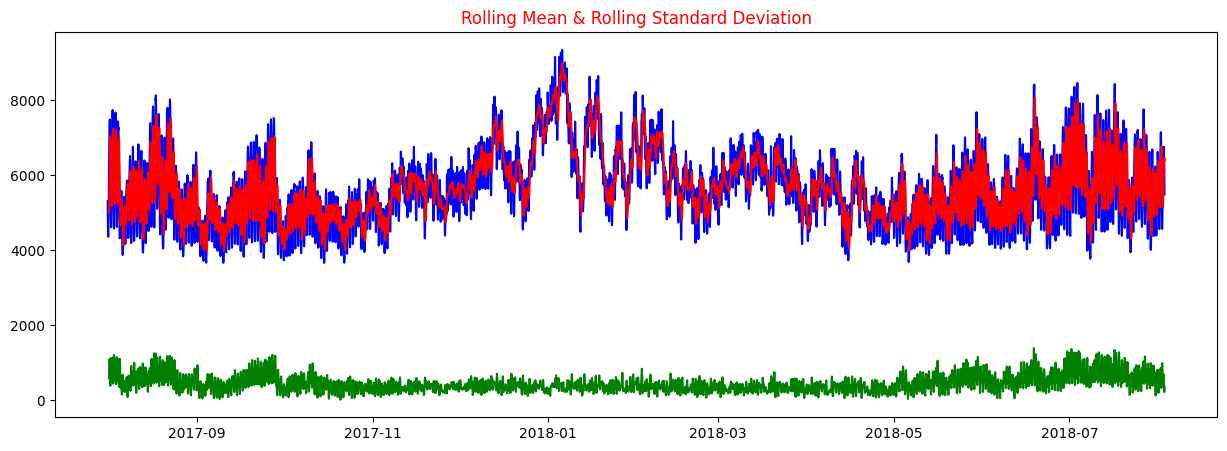

Test Statistics          -6.290434e+00
P_vlue                    3.610443e-08
#Lags                     3.700000e+01
Number of Observations    8.771000e+03
Critical_value (1%)      -3.431096e+00
Critical_value (5%)      -2.861870e+00
Critical_value (10%)     -2.566945e+00
dtype: float64


In [62]:
from IPython.core.completer import time
# For building the ARIMA model we have to check the stationarity of the data

def test_stationarity(time_series):

# Claculating the Roling mean and Rolling STD_DEV

  rolmean= time_series.rolling(window=12).mean()
  rolstd= time_series.rolling(window=12).std()

# Plotting the Original, mean and std
  plt.figure(figsize=(15,5))
  original= plt.plot(time_series, color="blue",label="Original")
  mean= plt.plot(rolmean, color="Red",label="Rolling_Mean")
  std= plt.plot(rolstd, color="Green",label="Rollong_std_dev")
  plt.title("Rolling Mean & Rolling Standard Deviation",color="Red")
  plt.show()

# Also perform ADCFULLER test as it will clear that the data is stationarity or not

  df_test= adfuller(time_series)
  my_output = pd.Series(df_test[0:4],index=["Test Statistics","P_vlue","#Lags","Number of Observations"])

  for i, j in df_test[4].items():
    my_output["Critical_value (%s)" %i]=j
  print(my_output)

test_stationarity(data["PJMW_MW"])

# **Summary of ADFULLER**

We can see that **critical value (5%)** =  -2.8
and **test statistic**s = -6.2
**p_value** =  3.6

**As per the rule of Hypothesis testing.**

**H0**= The data is not stationarity
**Ha**= The data is stationarity

**-- Critical value being the alpha/2**

and if we make a normal curve it would be placed out side the curve and alpha region that proves that the data is **stationarity**

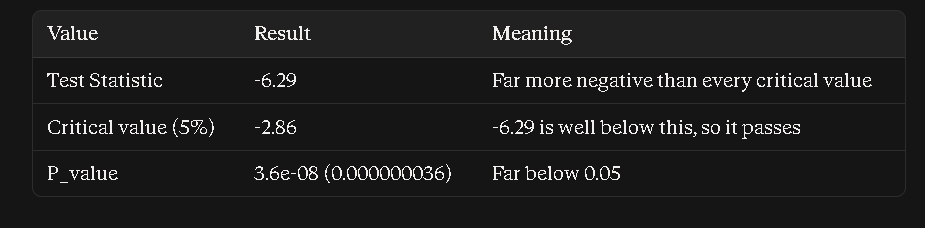

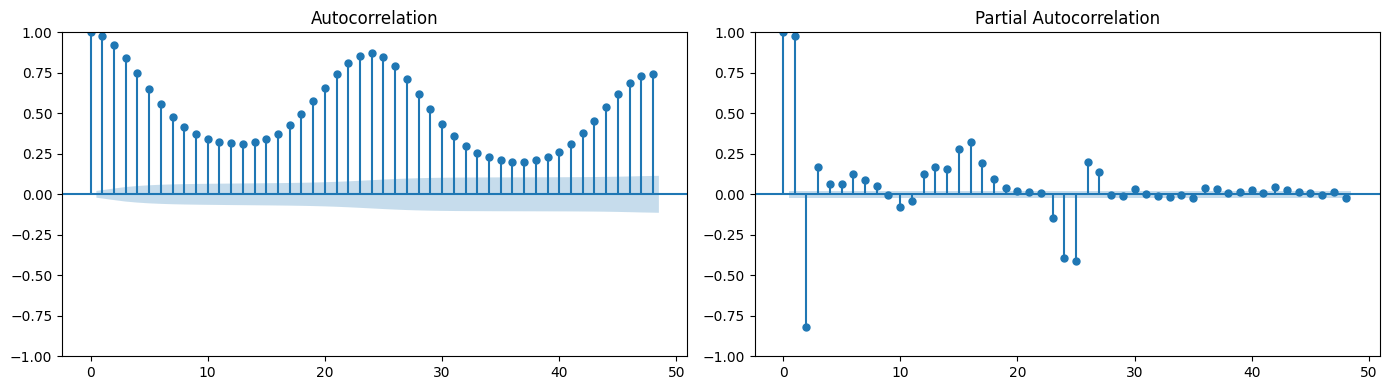

In [63]:
# As the data is at stationarity, we would now find the "ACF" & "PACF"

fig, axes = plt.subplots(1,2, figsize=(14,4))
smt.graphics.plot_acf(data["PJMW_MW"], lags=48, ax=axes[0])
smt.graphics.plot_pacf(data["PJMW_MW"], lags=48, ax=axes[1])
plt.tight_layout()

# **We can see from the ACF and PACF plot.**

**P value:** We have only two spikes potruding, (1 and 2)

**q value:** It is generally going very smooth and we can notice that
         we are repeating the pattern after every 24 sticks.

So we will take these value:

**p value:** 1 and 2
**q value:** we would be taking 0,1,2,3 etc to test for the best combination.

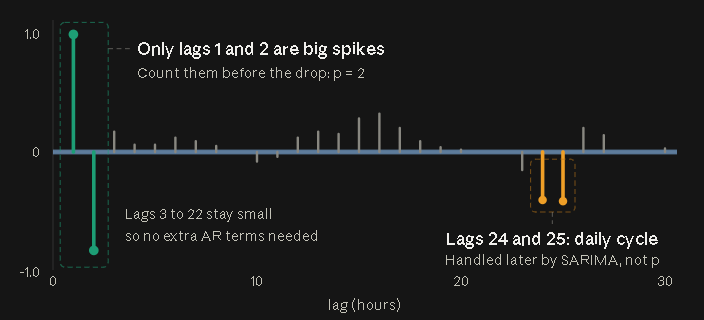

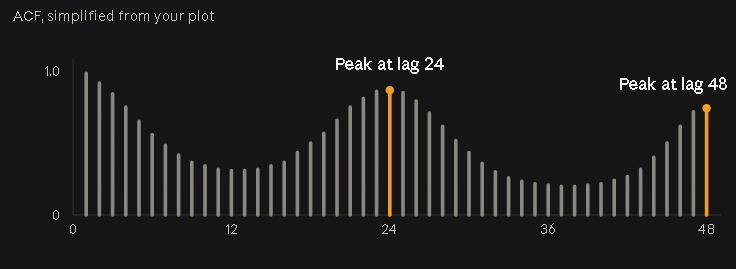

In [64]:
y_ts = data["PJMW_MW"]
train_ts = y_ts.iloc[:-168]
test_ts  = y_ts.iloc[-168:]

model = ARIMA(train_ts, order=(2, 0, 1))
result = model.fit()

pred = result.predict(start=test_ts.index[0], end=test_ts.index[-1])

print(pred.shape)
pred.tail()

(168,)


,predicted_mean
2018-08-02 20:00:00,5703.985591
2018-08-02 21:00:00,5703.985591
2018-08-02 22:00:00,5703.985591
2018-08-02 23:00:00,5703.985591
2018-08-03 00:00:00,5703.985591


# **Error Metrics**

In [65]:
# RMSE
rmse = np.sqrt(mean_squared_error(test_ts, pred))

# MAE
mae  = mean_absolute_error(test_ts, pred)

# MAPE
mape = (abs(test_ts - pred) / test_ts).mean() * 100
print(f"RMSE: {rmse:.1f} | MAE: {mae:.1f} | MAPE: {mape:.2f}%")

RMSE: 849.9 | MAE: 732.2 | MAPE: 13.58%


In [66]:
# Accuracy of ARIMA

acc_arima  = 100 - mape
print(f"ARIMA accuracy   : {acc_arima:.2f}%")

ARIMA accuracy   : 86.42%


# **2) SARIMAX**

In [67]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [68]:
# we are taking the same variable names with a little distinction so the ARIMA model may stay untouched

In [69]:
# We will be using : p value, q value, sp: seasonal p value, sq: seasonal q value

In [70]:
# Model define
model_s = SARIMAX(train_ts, order=(2, 0, 1), seasonal_order=(1, 1, 1, 24))
result_s = model_s.fit(disp=False)

# Prediction
pred_s = result_s.predict(start=test_ts.index[0], end=test_ts.index[-1])

print(pred_s.shape)
pred_s.tail()

(168,)


,predicted_mean
2018-08-02 20:00:00,6888.272560
2018-08-02 21:00:00,6660.195607
2018-08-02 22:00:00,6473.792673
2018-08-02 23:00:00,6001.198260
2018-08-03 00:00:00,5548.633931


# **Error Metrics for SARIMAX**

In [71]:
# RMSE
rmse_s = np.sqrt(mean_squared_error(test_ts, pred_s))

# MAE
mae_s  = mean_absolute_error(test_ts, pred_s)

# MAPE
mape_s = (abs(test_ts - pred_s) / test_ts).mean() * 100
print(f"SARIMAX -> RMSE: {rmse_s:.1f} | MAE: {mae_s:.1f} | MAPE: {mape_s:.2f}%")

SARIMAX -> RMSE: 475.4 | MAE: 379.4 | MAPE: 6.83%


In [72]:
# Accuracy of SARIMAX

acc_sarima = 100 - mape_s
print(f"SARIMAX accuracy : {acc_sarima:.2f}%")

SARIMAX accuracy : 93.17%


## **Comparisson of ARIMA & SARIMAX Accuracy**

In [73]:
acc_arima  = 100 - mape
acc_sarima = 100 - mape_s
print(f"ARIMA accuracy   : {acc_arima:.2f}%")
print(f"SARIMAX accuracy : {acc_sarima:.2f}%")

ARIMA accuracy   : 86.42%
SARIMAX accuracy : 93.17%


### **Plot (ARIMA vs SARIMAX)**

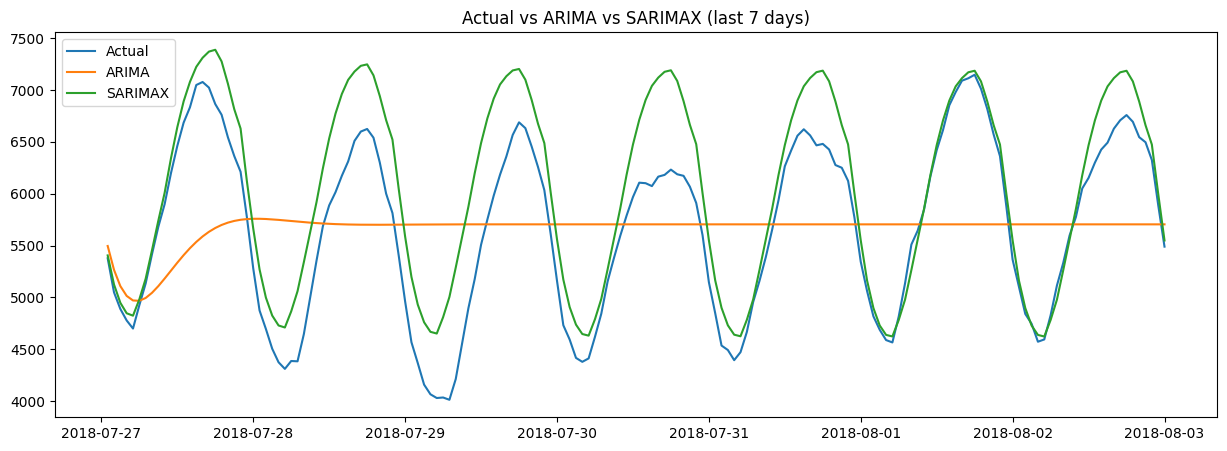

In [74]:
plt.figure(figsize=(15, 5))
plt.plot(test_ts, label="Actual")
plt.plot(pred, label="ARIMA")
plt.plot(pred_s, label="SARIMAX")
plt.legend()
plt.title("Actual vs ARIMA vs SARIMAX (last 7 days)")
plt.show()

# **3) LINEAR REGRESSION**

In [75]:
# Splitting the tatrget & features for the model building

target1   = df1[["PJMW_MW"]]
features1 = df1.drop(columns=["PJMW_MW", "Datetime", "monthname"])

In [76]:
# Train_test_split

from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(features1, target1, train_size=0.8, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(114451, 11)
(28613, 11)
(114451, 1)
(28613, 1)


In [77]:
X_train.head()

,Year,Month,Day,Hour,DayOfWeek,Weekend,Season,Holiday,Lag_1,Lag_24,Lag_168
127745,2016,11,2,18,2,0,3,0,5276.0,5227.0,5442.0
120429,2016,1,2,22,5,1,0,0,6110.0,5885.0,4928.0
32427,2005,12,19,4,0,0,0,0,5940.0,5826.0,5805.0
102888,2014,1,2,1,3,0,0,0,5579.0,5896.0,5644.0
57319,2008,10,21,8,1,0,3,0,5461.0,6037.0,5136.0


In [78]:
# Linear regression

from sklearn.linear_model import LinearRegression

lin=LinearRegression()
lin.fit(X_train,Y_train)

LinearRegression()

In [79]:
# Prediction & Accuracy

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error

# Prediction
lin_pred= lin.predict(X_test)

# Accuracy

lin_acc= r2_score(Y_test, lin_pred)
print(f"Accuracy : {lin_acc*100:.2f}%")

Accuracy : 96.00%


### **Error metrics**

In [80]:
# MAE
ln_mae =  mean_absolute_error(Y_test, lin_pred)

# MSE
ln_mse =  mean_squared_error(Y_test, lin_pred)

# RMSE
ln_rmse = np.sqrt(mean_squared_error(Y_test, lin_pred))

print(f"Linear regression -> MAE {ln_mae:.1f} | MSE {ln_mse:.1f} | RMSE {ln_rmse:.1f}")

Linear regression -> MAE 153.1 | MSE 38656.6 | RMSE 196.6


# **4) RANDOM FOREST**

In [81]:
# Importing the package

from sklearn.ensemble import RandomForestRegressor

In [82]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Training the model

rf.fit(X_train,Y_train)

# prediction

rf_pred =  rf.predict(X_test)

# Accuracy

rf_acc = r2_score(Y_test, rf_pred)
print(f"Accuracy : {rf_acc*100:.2f}%")

Accuracy : 99.43%


### **Error Metrics**

In [83]:
# MAE
rf_mae =  mean_absolute_error(Y_test, rf_pred)

# MSE
rf_mse =  mean_squared_error(Y_test, rf_pred)

# RMSE
rf_rmse = np.sqrt(mean_squared_error(Y_test, rf_pred))

print(f"Linear regression -> MAE {rf_mae:.1f} | MSE {rf_mse:.1f} | RMSE {rf_rmse:.1f}")

Linear regression -> MAE 54.1 | MSE 5473.6 | RMSE 74.0


# **5) XGBOOST**

In [84]:
# Importing the library

from xgboost import XGBRegressor

In [85]:
xgb = XGBRegressor(n_estimators= 100, random_state=42)

# Training the model

xgb.fit(X_train, Y_train)

# Prediction

xgb_pred = xgb.predict(X_test)

# Accuracy

xgb_acc = r2_score(Y_test, xgb_pred)
print(f"Accuracy : {xgb_acc*100:.2f}%")

Accuracy : 99.46%


### **Error Metrics**

In [86]:
# MAE
xgb_mae =  mean_absolute_error(Y_test, xgb_pred)

# MSE
xgb_mse =  mean_squared_error(Y_test, xgb_pred)

# RMSE
xgb_rmse = np.sqrt(mean_squared_error(Y_test, xgb_pred))

print(f"Linear regression -> MAE {xgb_mae:.1f} | MSE {xgb_mse:.1f} | RMSE {xgb_rmse:.1f}")

Linear regression -> MAE 53.8 | MSE 5235.0 | RMSE 72.4


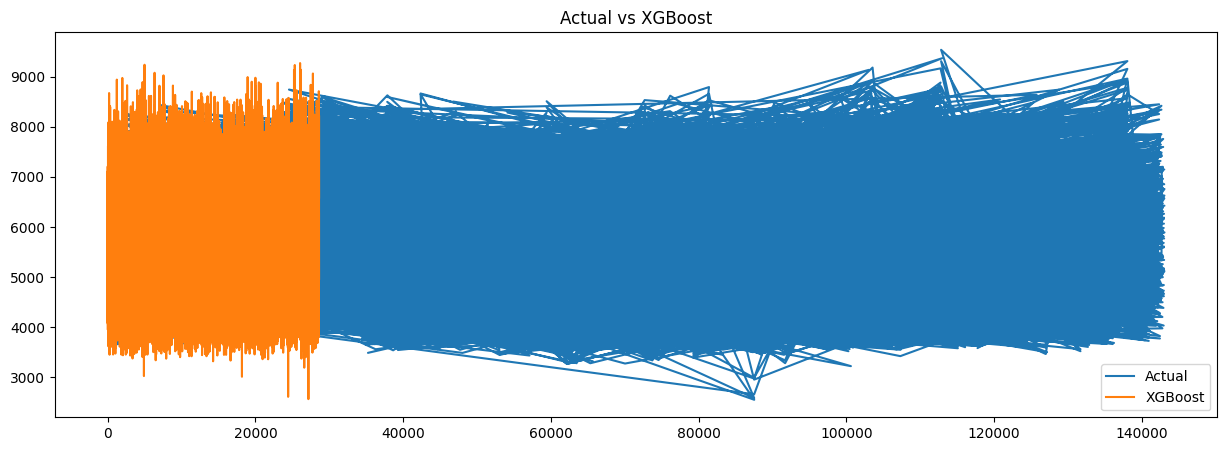

In [87]:
# ACTUAL vs PREDICTION

plt.figure(figsize=(15,5))
plt.plot(Y_test, label="Actual")
plt.plot(xgb_pred, label="XGBoost")
plt.legend()
plt.title("Actual vs XGBoost")
plt.show()

# **6) Simple Exponential Smoothing**

In [88]:
# importing the package

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

In [89]:
# we would denote everything with ses

model_ses = SimpleExpSmoothing(train_ts, initialization_method="estimated")
result_ses = model_ses.fit()

# Prediction

pred_ses = result_ses.predict(start=test_ts.index[0], end=test_ts.index[-1])

In [90]:
# Accuracy

rmse_ses = np.sqrt(mean_squared_error(test_ts, pred_ses))
mae_ses = mean_absolute_error(test_ts, pred_ses)
mape_ses = (abs(test_ts - pred_ses) / test_ts).mean() * 100

In [91]:
print(f"Simple Exponential Smoothing -> RMSE: {rmse_ses:.1f} | MAE: {mae_ses:.1f} | MAPE: {mape_ses:.2f}%")
print(f"Accuracy: {100-mape_ses:.2f}%")

Simple Exponential Smoothing -> RMSE: 856.0 | MAE: 733.4 | MAPE: 13.93%
Accuracy: 86.07%


# **7) Prophet**

In [92]:
# import package

from prophet import Prophet

In [93]:
# model train

prophet_train = train_ts.reset_index()
prophet_train.columns = ["ds", "y"]

model_prophet = Prophet()
model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(periods=len(test_ts), freq="h")

forecast = model_prophet.predict(future)

pred_prophet = forecast["yhat"].iloc[-len(test_ts):].values

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.


In [94]:
# Accuracy

rmse_prophet = np.sqrt(mean_squared_error(test_ts, pred_prophet))
mae_prophet = mean_absolute_error(test_ts, pred_prophet)
mape_prophet = np.mean(np.abs((test_ts - pred_prophet) / test_ts)) * 100

print(f"Prophet -> RMSE: {rmse_prophet:.1f} | MAE: {mae_prophet:.1f} | MAPE: {mape_prophet:.2f}%")
print("Accuracy:", round(100 - mape_prophet, 2), "%")

Prophet -> RMSE: 723.9 | MAE: 626.8 | MAPE: 12.14%
Accuracy: 87.86 %


# Model Performance Comparison

After developing and evaluating the different forecasting and machine learning models, their performance was compared using the evaluation metrics obtained on the test data. The main evaluation metrics considered were **MAE (Mean Absolute Error), RMSE (Root Mean Squared Error), MAPE (Mean Absolute Percentage Error), and Accuracy/R²**, depending on the model.

A lower value of MAE, RMSE, and MAPE indicates lower prediction error, while a higher R² value indicates that the model explains a larger proportion of the variation in the target variable.

## Accuracy Comparison of Models

| Model | Accuracy / R² (%) | MAE | RMSE | MAPE (%) |
|---|---:|---:|---:|---:|
| **XGBoost** | **99.46** | **53.8** | **72.4** | — |
| **Random Forest** | **99.43** | **54.1** | **74.0** | — |
| **Linear Regression** | **96.00** | 153.1 | 196.6 | — |
| **SARIMAX** | **93.17** | 379.4 | 475.4 | **6.83** |
| **Prophet** | **87.86** | 626.8 | 723.9 | 12.14 |
| **ARIMA** | **86.42** | 732.2 | 849.9 | 13.58 |
| **Simple Exponential Smoothing** | **86.07** | 733.4 | 856.0 | 13.93 |

> **Note:** The accuracy values are not calculated using exactly the same methodology for every model. For the machine learning models, accuracy is based on **R² × 100**, whereas the time-series models use **100 − MAPE**. Therefore, the accuracy percentages should be interpreted within their respective evaluation approaches. MAE and RMSE provide additional information about the magnitude of prediction errors.

## Model Performance Analysis

The comparison shows that the machine learning models achieved relatively lower prediction errors on the test data. **XGBoost** recorded an R²-based accuracy of **99.46%**, with an MAE of **53.8 MW** and an RMSE of **72.4 MW**. **Random Forest** produced a very similar result, with an accuracy of **99.43%**, MAE of **54.1 MW**, and RMSE of **74.0 MW**.

**Linear Regression** achieved an R²-based accuracy of **96.00%**, with an MAE of **153.1 MW** and RMSE of **196.6 MW**. This indicates that the relationship captured by the linear model was useful for prediction, although its errors were higher than those observed for the tree-based ensemble models.

Among the time-series forecasting models, **SARIMAX** achieved the highest reported accuracy, at **93.17%**, with a MAPE of **6.83%**, MAE of **379.4 MW**, and RMSE of **475.4 MW**. This indicates that incorporating seasonal and time-dependent patterns improved forecasting performance compared with the basic ARIMA and Simple Exponential Smoothing approaches.

**Prophet** achieved an accuracy of **87.86%**, while **ARIMA** and **Simple Exponential Smoothing** achieved **86.42%** and **86.07%**, respectively.

Overall, the results demonstrate that different modelling approaches capture different characteristics of electricity consumption. The machine learning models were able to capture complex relationships between the available features, while the time-series models focused primarily on temporal and seasonal patterns.

# Project Summary

The project focused on analysing and forecasting **hourly electricity consumption** using the available historical electricity demand data.

The analysis started with **Exploratory Data Analysis (EDA)** to understand the structure and characteristics of the dataset. The dataset was examined for missing values, duplicate timestamps, abnormal observations, and important temporal patterns. Various time-based features and visualisations were used to understand electricity consumption across different hours, days, and seasonal periods.

Following the data preparation and EDA stages, multiple forecasting approaches were implemented. The project included traditional time-series models such as:

- ARIMA
- SARIMAX
- Simple Exponential Smoothing
- Prophet

Machine learning approaches were also developed:

- Linear Regression
- Random Forest
- XGBoost

The models were evaluated using appropriate performance metrics including **MAE, RMSE, MAPE, and R²-based accuracy**. This allowed the performance of the different approaches to be examined from multiple perspectives rather than relying on a single metric.

The analysis demonstrated that electricity consumption contains significant temporal and seasonal patterns. Incorporating these patterns into forecasting models helped improve the ability to predict future electricity demand.

# Conclusion

The project successfully demonstrated the complete process of **data preparation, exploratory data analysis, feature analysis, time-series modelling, machine learning modelling, forecasting, and model evaluation** for electricity consumption data.

The results indicate differences in performance between traditional time-series models and machine learning models. Among the machine learning models evaluated, **XGBoost and Random Forest produced the lowest MAE and RMSE values in the reported test results**, while Linear Regression also provided a strong baseline.

Among the time-series approaches, **SARIMAX produced lower forecasting errors than ARIMA, Prophet, and Simple Exponential Smoothing in the reported evaluation**. Its performance also demonstrates the importance of incorporating seasonal behaviour into electricity-demand forecasting.

The comparison highlights that model performance depends on how effectively the model captures the underlying patterns in the data. Machine learning models can capture complex relationships among explanatory variables, whereas time-series models explicitly model temporal dependencies and seasonality.

Therefore, the project demonstrates that electricity demand forecasting can be approached using both **traditional statistical forecasting techniques and machine learning techniques**, with each approach providing useful insights into the behaviour of the data.

## Key Findings

| Aspect | Finding |
|---|---|
| **Dataset** | Historical hourly electricity consumption data |
| **Target Variable** | Electricity consumption / demand in MW |
| **Forecasting Approach** | Time-series and machine learning models |
| **Time-Series Models** | ARIMA, SARIMAX, Simple Exponential Smoothing, Prophet |
| **Machine Learning Models** | Linear Regression, Random Forest, XGBoost |
| **Evaluation Metrics** | MAE, RMSE, MAPE and R²-based Accuracy |
| **Reported Lowest MAE** | XGBoost – 53.8 MW |
| **Reported Lowest RMSE** | XGBoost – 72.4 MW |
| **Time-Series MAPE** | SARIMAX – 6.83% |
| **Overall Observation** | Different models capture different temporal and feature-based patterns in electricity consumption |

## Final Observation

The modelling exercise shows the importance of **comparing multiple approaches rather than relying on a single forecasting technique**. The combination of EDA, feature engineering, time-series modelling, machine learning, and performance evaluation provides a comprehensive framework for analysing and forecasting electricity consumption.

# **DEPLOYMENT**

In [98]:
import json
import numpy as np
import pandas as pd
import holidays
from sklearn.metrics import r2_score

HORIZON = 720   # 30 days x 24 hours
HOLD = 168      # last 7 days used for the back-test


def metrics(actual, pred):
    a = np.asarray(actual, dtype=float).ravel()
    p = np.asarray(pred, dtype=float).ravel()
    return {
        "MAE": np.mean(np.abs(a - p)),
        "RMSE": np.sqrt(np.mean((a - p) ** 2)),
        "MAPE (%)": np.mean(np.abs((a - p) / a)) * 100,
        "R2 (%)": r2_score(a, p) * 100,
    }


def save_artifacts(prefix, hourly, results, avp, meta):
    """Writes the 5 files the Streamlit app needs for ONE model."""
    daily = (
        hourly.set_index("Datetime")["Predicted_MW"]
        .resample("D").agg(["mean", "min", "max"]).reset_index()
    )
    daily.columns = ["Date", "Average_Predicted_MW",
                     "Minimum_Predicted_MW", "Maximum_Predicted_MW"]

    hourly.to_csv(f"{prefix}_hourly_forecast.csv", index=False)
    daily.to_csv(f"{prefix}_daily_forecast.csv", index=False)
    results.to_csv(f"{prefix}_model_results.csv", index=False)
    avp.to_csv(f"{prefix}_actual_vs_predicted.csv", index=False)
    with open(f"{prefix}_metadata.json", "w") as f:
        json.dump(meta, f, indent=2)

    print(f"{prefix}: forecast {hourly['Datetime'].min()} -> {hourly['Datetime'].max()} "
          f"| rows: {len(hourly)} | missing: {hourly['Predicted_MW'].isna().sum()}")

### **XGBOOST MODEL**

In [99]:
from xgboost import XGBRegressor

us_hol = holidays.US()
SEASON_MAP = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3}
FEATURES = list(X_train.columns)
LAGS = ["Lag_1", "Lag_24", "Lag_168"]


def calendar_features(index):
    return pd.DataFrame({
        "Year": index.year.to_numpy(),
        "Month": index.month.to_numpy(),
        "Day": index.day.to_numpy(),
        "Hour": index.hour.to_numpy(),
        "DayOfWeek": index.dayofweek.to_numpy(),
        "Weekend": (index.dayofweek >= 5).astype(int),
        "Season": [SEASON_MAP[m] for m in index.month],
        "Holiday": [int(d in us_hol) for d in index.date],
    })


def recursive_forecast(model, history, steps):
    """Forecast `steps` hours after the end of `history` (hourly pd.Series),
    feeding every prediction back in as the next hour's lag values."""
    index = pd.date_range(history.index[-1] + pd.Timedelta(hours=1), periods=steps, freq="h")
    X = calendar_features(index)
    for c in LAGS:
        X[c] = 0.0
    X = X[FEATURES]

    vals = list(history.values[-168:].astype(float))
    out = []
    for i in range(steps):
        X.loc[i, LAGS] = [vals[-1], vals[-24], vals[-168]]
        p = float(model.predict(X.iloc[[i]])[0])
        vals.append(p)
        out.append(p)
    return pd.Series(out, index=index)


# 1) Back-test: train up to 7 days before the end, then forecast those 7 days recursively
train_bt, test_bt = ts.iloc[:-HOLD], ts.iloc[-HOLD:]
mask = df1["Datetime"] <= train_bt.index[-1]
xgb_bt = XGBRegressor(n_estimators=100, random_state=42).fit(features1[mask], target1[mask])
bt_pred = recursive_forecast(xgb_bt, train_bt, HOLD)

# 2) Final model on ALL data -> 30-day forecast
xgb_final = XGBRegressor(n_estimators=100, random_state=42).fit(features1, target1)
fc_x = recursive_forecast(xgb_final, ts, HORIZON)
hourly_x = pd.DataFrame({"Datetime": fc_x.index, "Predicted_MW": np.clip(fc_x.values, 0, None)})

# 3) Results table (both evaluations are shown in the app)
results_x = pd.DataFrame([
    {"Evaluation": "Random 80/20 split (actual lags known)", **metrics(Y_test, xgb_pred)},
    {"Evaluation": "Last 7 days, recursive (no actual lags)", **metrics(test_bt, bt_pred)},
]).round(4)

avp_x = pd.DataFrame({"Datetime": test_bt.index,
                      "Actual_MW": test_bt.values,
                      "Predicted_MW": bt_pred.values})

meta_x = {
    "model_name": "XGBoost",
    "model_label": "XGBoost Regressor",
    "overview": [
        "This page uses a gradient-boosted tree model (XGBoost) trained on time-based "
        "features, holiday flags and lag features (previous hour, previous day, previous week).",
        "Because future lag values are unknown, the 30-day forecast is generated recursively: "
        "each predicted hour is used as the lag input for the following hours.",
    ],
    "avp_title": "Actual vs Predicted (last 7 days, recursive back-test)",
    "results_note": ("The random 80/20 split lets the model see the actual previous hour, so it looks "
                     "very accurate. The recursive row is the realistic one, because it forecasts "
                     "without any actual lag values, exactly like the 30-day forecast."),
    "details": {
        "Algorithm": "XGBRegressor (gradient-boosted trees)",
        "n_estimators": 100,
        "random_state": 42,
        "Features used": ", ".join(FEATURES),
        "Forecast method": "Recursive multi-step (predictions feed the lag features)",
        "Training rows": int(len(features1)),
        "Forecast horizon": f"{HORIZON} hours (30 days)",
        "Final model": "Refitted on the complete history before forecasting",
    },
    "feature_importance": dict(zip(FEATURES, [round(float(v), 4) for v in xgb_final.feature_importances_])),
    "notes": ["Recursive forecasts accumulate error, so the later days of the 30-day horizon "
              "are less reliable than the first few days."],
    "forecast_horizon_hours": HORIZON,
}

save_artifacts("pjm_xgboost", hourly_x, results_x, avp_x, meta_x)
results_x

pjm_xgboost: forecast 2018-08-03 01:00:00 -> 2018-09-02 00:00:00 | rows: 720 | missing: 0


,Evaluation,MAE,RMSE,MAPE (%),R2 (%)
0,Random 80/20 split (actual lags known),53.8415,72.3534,0.9645,99.4582
1,"Last 7 days, recursive (no actual lags)",294.6759,430.2409,4.9404,74.0016


In [97]:
# As we have XGBOOST model with the highest accuracy score of 99.46% so here we are going to use the deployment model for it.

### **SARIMAX MODEL**

In [100]:
res_full = result_s.append(test_ts)            # same parameters, updated with the latest 168 hours
fc_s = res_full.forecast(steps=HORIZON)
hourly_s = pd.DataFrame({"Datetime": fc_s.index, "Predicted_MW": np.clip(fc_s.values, 0, None)})

results_s = pd.DataFrame([
    {"Evaluation": "Last 7 days (168 h) hold-out", **metrics(test_ts, pred_s)},
]).round(4)

avp_s = pd.DataFrame({"Datetime": test_ts.index,
                      "Actual_MW": test_ts.values,
                      "Predicted_MW": np.asarray(pred_s)})

meta_s = {
    "model_name": "SARIMAX",
    "model_label": "SARIMAX(2,0,1)x(1,1,1,24)",
    "overview": [
        "This page uses a seasonal time-series model (SARIMAX) that learns the autoregressive, "
        "moving-average and 24-hour seasonal structure of the hourly demand history.",
        "The model forecasts the next 30 days directly from the seasonal history, "
        "so it needs no future lag values.",
    ],
    "avp_title": "Actual vs Predicted (last 7 days hold-out)",
    "results_note": "SARIMAX was scored on the last 7 days (168 hours) of data that it did not train on.",
    "details": {
        "Algorithm": "SARIMAX",
        "Order (p, d, q)": "(2, 0, 1)",
        "Seasonal order (P, D, Q, s)": "(1, 1, 1, 24)",
        "Seasonal period": "24 hours",
        "Training window": f"{int(len(train_ts))} hours (from 2017-08-01)",
        "AIC": round(float(result_s.aic), 2),
        "Forecast method": "Direct multi-step forecast from the seasonal state",
        "Forecast horizon": f"{HORIZON} hours (30 days)",
    },
    "feature_importance": {},
    "notes": ["Parameters were estimated on the training window and the state was then updated "
              "with the latest 168 hours before forecasting (no refit)."],
    "forecast_horizon_hours": HORIZON,
}

save_artifacts("pjm_sarimax", hourly_s, results_s, avp_s, meta_s)
results_s

pjm_sarimax: forecast 2018-08-03 01:00:00 -> 2018-09-02 00:00:00 | rows: 720 | missing: 0


,Evaluation,MAE,RMSE,MAPE (%),R2 (%)
0,Last 7 days (168 h) hold-out,379.3792,475.351,6.8256,68.264


In [101]:
%%writefile app.py
import os
import json

import holidays
import pandas as pd
import streamlit as st

st.set_page_config(page_title="PJM Energy Forecast", page_icon="⚡", layout="wide")

MODEL_PREFIX = {"XGBoost": "pjm_xgboost", "SARIMAX": "pjm_sarimax"}
PAGES = ["Overview", "Model Performance", "30-Day Forecast", "Forecast Data"]

# ---------------- Sidebar ----------------
st.sidebar.markdown("## ⚡ PJM Energy Forecast")
model_name = st.sidebar.radio("Select model:", list(MODEL_PREFIX), key="model")
st.sidebar.header("Navigation")
page = st.sidebar.radio("Go to:", PAGES, key="page")

prefix = MODEL_PREFIX[model_name]
FILES = [
    f"{prefix}_hourly_forecast.csv",
    f"{prefix}_daily_forecast.csv",
    f"{prefix}_model_results.csv",
    f"{prefix}_actual_vs_predicted.csv",
    f"{prefix}_metadata.json",
]
missing = [f for f in FILES if not os.path.exists(f)]
if missing:
    st.error(f"Missing files for {model_name}: " + ", ".join(missing) +
             ". Please re-run the notebook cells that save the deployment files.")
    st.stop()


@st.cache_data
def load_data(prefix):
    hourly = pd.read_csv(f"{prefix}_hourly_forecast.csv", parse_dates=["Datetime"])
    daily = pd.read_csv(f"{prefix}_daily_forecast.csv", parse_dates=["Date"])
    results = pd.read_csv(f"{prefix}_model_results.csv")
    avp = pd.read_csv(f"{prefix}_actual_vs_predicted.csv", parse_dates=["Datetime"])
    with open(f"{prefix}_metadata.json") as f:
        meta = json.load(f)
    return hourly, daily, results, avp, meta


hourly, daily, results, avp, meta = load_data(prefix)

# ---------------- Page 1: Overview ----------------
if page == "Overview":
    st.title(f"⚡ PJM Hourly Energy Consumption Forecast: {model_name}")
    st.write(f"{model_name} based forecasting of PJM electricity consumption for the next 30 days.")

    st.header("Project Overview")
    st.write("The objective of this project is to analyze historical PJM electricity consumption "
             "data and forecast future energy consumption.")
    for para in meta["overview"]:
        st.write(para)
    st.write(f"{meta['model_label']} is the model used for the forecast shown on these pages.")

    st.header("Forecast Summary")
    c1, c2, c3, c4, c5 = st.columns(5)
    c1.metric("Forecast Hours", len(hourly))
    c2.metric("Forecast Days", len(hourly) // 24)
    c3.metric("Average MW", f"{hourly['Predicted_MW'].mean():.2f}")
    c4.metric("Maximum MW", f"{hourly['Predicted_MW'].max():.2f}")
    c5.metric("Minimum MW", f"{hourly['Predicted_MW'].min():.2f}")

    st.header("Daily Forecast")
    st.line_chart(daily.set_index("Date")["Average_Predicted_MW"])

# ---------------- Page 2: Model Performance ----------------
elif page == "Model Performance":
    st.title(f"📊 Model Performance: {model_name}")
    st.write(f"Evaluation results of the {model_name} model.")

    metric_cols = ["Evaluation", "MAE", "RMSE", "MAPE (%)", "R2 (%)"]
    st.dataframe(results[metric_cols])
    if meta.get("results_note"):
        st.caption(meta["results_note"])

    st.header(meta.get("avp_title", "Actual vs Predicted"))
    st.line_chart(avp.set_index("Datetime")[["Actual_MW", "Predicted_MW"]])

    if meta.get("feature_importance"):
        st.header("Feature Importance")
        fi = (pd.Series(meta["feature_importance"], name="Importance")
              .sort_values(ascending=False).to_frame())
        st.bar_chart(fi)

    st.header("Final Model")
    st.success(f"{meta['model_label']} is the model used for this forecast.")
    for _, r in results.iterrows():
        st.markdown(f"**{r['Evaluation']}**")
        m1, m2, m3, m4 = st.columns(4)
        m1.metric("MAE", f"{r['MAE']:.2f} MW")
        m2.metric("RMSE", f"{r['RMSE']:.2f} MW")
        m3.metric("MAPE", f"{r['MAPE (%)']:.2f}%")
        m4.metric("R²", f"{r['R2 (%)']:.2f}%")

    st.header("Model Information")
    for k, v in meta["details"].items():
        st.write(f"**{k}:** {v}")
    for note in meta.get("notes", []):
        st.info(note)

# ---------------- Page 3: 30-Day Forecast ----------------
elif page == "30-Day Forecast":
    st.title(f"📈 30-Day Energy Consumption Forecast: {model_name}")

    st.header("Hourly Forecast")
    st.line_chart(hourly.set_index("Datetime")["Predicted_MW"])

    st.header("Daily Average Forecast")
    st.line_chart(daily.set_index("Date")["Average_Predicted_MW"])

# ---------------- Page 4: Forecast Data ----------------
else:
    st.title(f"📋 Forecast Data: {model_name}")
    st.write("Hourly energy consumption predictions for the next 30 days.")

    us_holidays = holidays.US()
    table = hourly.copy()
    table["Hour"] = table["Datetime"].dt.hour
    table["DayOfWeek"] = table["Datetime"].dt.dayofweek
    table["Month"] = table["Datetime"].dt.month
    table["Year"] = table["Datetime"].dt.year
    table["IsWeekend"] = (table["DayOfWeek"] >= 5).astype(int)
    table["IsHoliday"] = table["Datetime"].dt.date.apply(lambda d: d in us_holidays).astype(int)
    table["Predicted_MW"] = table["Predicted_MW"].round(2)
    table = table[["Datetime", "Hour", "DayOfWeek", "Month", "Year",
                   "IsWeekend", "IsHoliday", "Predicted_MW"]]

    st.dataframe(table)
    st.download_button(
        "Download forecast as CSV",
        table.to_csv(index=False).encode("utf-8"),
        file_name=f"{prefix}_30_day_forecast.csv",
        mime="text/csv",
        key=f"download_{prefix}",
    )

Writing app.py


In [103]:
!pip install -q streamlit pyngrok holidays

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 21.6 MB/s eta 0:00:00


In [104]:
import os
os.makedirs(".streamlit", exist_ok=True)
with open(".streamlit/config.toml", "w") as f:
    f.write('[theme]\nbase = "dark"\n')

from streamlit.testing.v1 import AppTest

at = AppTest.from_file("/content/app.py", default_timeout=120).run()
for m in ["XGBoost", "SARIMAX"]:
    for p in ["Overview", "Model Performance", "30-Day Forecast", "Forecast Data"]:
        at.sidebar.radio(key="model").set_value(m)
        at.sidebar.radio(key="page").set_value(p)
        at.run()
        print(f"{m:8s} | {p:20s} -> exceptions: {len(at.exception)} | errors: {len(at.error)}")

2026-10-07 09:29:08.624 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


XGBoost  | Overview             -> exceptions: 0 | errors: 0
XGBoost  | Model Performance    -> exceptions: 0 | errors: 0
XGBoost  | 30-Day Forecast      -> exceptions: 0 | errors: 0
XGBoost  | Forecast Data        -> exceptions: 0 | errors: 0
SARIMAX  | Overview             -> exceptions: 0 | errors: 0
SARIMAX  | Model Performance    -> exceptions: 0 | errors: 0
SARIMAX  | 30-Day Forecast      -> exceptions: 0 | errors: 0
SARIMAX  | Forecast Data        -> exceptions: 0 | errors: 0


In [105]:
import time, getpass
from pyngrok import ngrok

ngrok_keys = getpass.getpass("Enter Ngrok key: ")

ngrok.kill()
!pkill -f streamlit

!nohup streamlit run app.py --server.port 8501 --server.headless true > /content/logs.txt 2>&1 &
time.sleep(10)

ngrok.set_auth_token(ngrok_keys)
print(ngrok.connect(8501).public_url)

Enter Ngrok key: ··········
https://heave-patio-substance.ngrok-free.dev
